In [10]:
!pip install statsmodels -q

In [11]:
import pandas as pd
import numpy as np
import pickle
import json
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report, accuracy_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import matplotlib.pyplot as plt


In [12]:
from google.colab import files
uploaded = files.upload()
csv_path = list(uploaded.keys())[0]

Saving Lead Scoring.csv.zip to Lead Scoring.csv (1).zip


In [13]:
RANDOM_STATE = 42

LEAKAGE_COLS = [
    'Tags', 'Lead Quality', 'Asymmetrique Activity Index', 'Asymmetrique Profile Index',
    'Asymmetrique Activity Score', 'Asymmetrique Profile Score', 'Last Notable Activity',
    'Lead Profile'
]
ID_COLS = ['Prospect ID', 'Lead Number']
CONSTANT_COLS = [
    'Magazine', 'Receive More Updates About Our Courses', 'Update me on Supply Chain Content',
    'Get updates on DM Content', 'I agree to pay the amount through cheque'
]
NUMERIC_COLS = ['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']
BINARY_COLS = [
    'Do Not Email', 'Do Not Call', 'Search', 'Newspaper Article', 'X Education Forums',
    'Newspaper', 'Digital Advertisement', 'Through Recommendations',
    'A free copy of Mastering The Interview'
]
CATEGORICAL_COLS = [
    'Lead Origin', 'Lead Source', 'Last Activity', 'Country', 'Specialization',
    'How did you hear about X Education', 'What is your current occupation',
    'What matters most to you in choosing a course', 'City'
]

In [14]:
def load_and_clean(path):
    df = pd.read_csv(path)
    df = df.replace('Select', np.nan)

    df = df.drop(columns=[c for c in LEAKAGE_COLS + CONSTANT_COLS if c in df.columns])
    ids = df[ID_COLS].copy()
    df = df.drop(columns=ID_COLS)

    for col in ['TotalVisits', 'Page Views Per Visit']:
        df[col] = df[col].fillna(df[col].median())
    df['Total Time Spent on Website'] = df['Total Time Spent on Website'].fillna(0)

    df['Last Activity'] = df['Last Activity'].fillna('Unknown')
    df['Lead Source'] = df['Lead Source'].fillna('Unknown').replace({'google': 'Google'})
    df['Country'] = df['Country'].fillna('Unknown')
    top_countries = df['Country'].value_counts().nlargest(5).index
    df['Country'] = df['Country'].apply(lambda x: x if x in top_countries else 'Other')

    df['Specialization'] = df['Specialization'].fillna('Not Specified')
    df['What is your current occupation'] = df['What is your current occupation'].fillna('Unknown')
    df['What matters most to you in choosing a course'] = df['What matters most to you in choosing a course'].fillna('Unknown')
    df['How did you hear about X Education'] = df['How did you hear about X Education'].fillna('Unknown')
    df['City'] = df['City'].fillna('Unknown')

    for col in df.select_dtypes(include='object').columns:
        vc = df[col].value_counts(normalize=True)
        rare = vc[vc < 0.01].index
        df[col] = df[col].apply(lambda x: 'Other' if x in rare else x)

    return df, ids

def cap_outliers(df, cols):
    df = df.copy()
    for col in cols:
        q1 = df[col].quantile(0.01)
        q99 = df[col].quantile(0.99)
        df[col] = df[col].clip(q1, q99)
    return df

In [15]:
df, ids = load_and_clean(csv_path)
df = cap_outliers(df, NUMERIC_COLS)

for col in BINARY_COLS:
    df[col] = df[col].map({'Yes': 1, 'No': 0}).fillna(0).astype(int)

df.isnull().sum().sum()

np.int64(0)

In [16]:
def clean_name(c):
    return c.replace(' ', '_').replace('/', '_').replace('&', 'and')

df_encoded = pd.get_dummies(df, columns=CATEGORICAL_COLS, drop_first=True)
dummy_cols = [c for c in df_encoded.columns if df_encoded[c].dtype == bool]
df_encoded[dummy_cols] = df_encoded[dummy_cols].astype(int)

y = df_encoded['Converted']
X = df_encoded.drop(columns=['Converted'])

rename_map = {c: clean_name(c) for c in X.columns}
X = X.rename(columns=rename_map)
NUMERIC_COLS_CLEAN = [clean_name(c) for c in NUMERIC_COLS]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train[NUMERIC_COLS_CLEAN] = scaler.fit_transform(X_train[NUMERIC_COLS_CLEAN])
X_test[NUMERIC_COLS_CLEAN] = scaler.transform(X_test[NUMERIC_COLS_CLEAN])

In [18]:
lr = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
rfe = RFE(lr, n_features_to_select=20)
rfe = rfe.fit(X_train, y_train)
selected_features = X_train.columns[rfe.support_].tolist()
selected_features

['Do_Not_Email',
 'Total_Time_Spent_on_Website',
 'Lead_Origin_Landing_Page_Submission',
 'Lead_Origin_Lead_Add_Form',
 'Lead_Origin_Other',
 'Lead_Source_Welingak_Website',
 'Last_Activity_Email_Opened',
 'Last_Activity_Olark_Chat_Conversation',
 'Last_Activity_Other',
 'Last_Activity_SMS_Sent',
 'Country_Unknown',
 'Specialization_Hospitality_Management',
 'Specialization_Not_Specified',
 'Specialization_Retail_Management',
 'What_is_your_current_occupation_Student',
 'What_is_your_current_occupation_Unemployed',
 'What_is_your_current_occupation_Unknown',
 'What_is_your_current_occupation_Working_Professional',
 'What_matters_most_to_you_in_choosing_a_course_Unknown',
 'City_Unknown']

In [19]:
def vif_prune(X_sub, threshold=5.0):
    cols = list(X_sub.columns)
    while True:
        X_const = sm.add_constant(X_sub[cols])
        vifs = pd.Series(
            [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])],
            index=cols
        )
        if vifs.max() > threshold and len(cols) > 1:
            cols.remove(vifs.idxmax())
        else:
            break
    return cols

final_features = vif_prune(X_train[selected_features])

In [20]:
def pvalue_prune(X_sub, y_sub, p_threshold=0.05):
    cols = list(X_sub.columns)
    while True:
        X_const = sm.add_constant(X_sub[cols])
        model = sm.Logit(y_sub, X_const).fit(disp=0)
        pvals = model.pvalues.drop('const')
        if pvals.max() > p_threshold and len(cols) > 1:
            cols.remove(pvals.idxmax())
        else:
            return cols, model

final_features, sm_model = pvalue_prune(X_train[final_features], y_train)
sm_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              Converted   No. Observations:                 6468
Model:                          Logit   Df Residuals:                     6452
Method:                           MLE   Df Model:                           15
Date:                Sat, 08 Aug 2026   Pseudo R-squ.:                  0.4138
Time:                        04:23:10   Log-Likelihood:                -2527.7
converged:                       True   LL-Null:                       -4312.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
=========================================================================================================================
                                                            coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
const                                                    -0.4894      0.144     -3.404      0.001      -0.771      -0.208
Do_Not_Email                                             -1.4548      0.180     -8.075      0.000      -1.808      -1.102
Total_Time_Spent_on_Website                               1.1070      0.041     26.956      0.000       1.027       1.187
Lead_Origin_Landing_Page_Submission                      -1.2299      0.128     -9.605      0.000      -1.481      -0.979
Lead_Origin_Lead_Add_Form                                 1.7472      0.216      8.097      0.000       1.324       2.170
Lead_Origin_Other                                        -1.4479      0.438     -3.306      0.001      -2.306      -0.590
Lead_Source_Welingak_Website                              2.3713      0.746      3.179      0.001       0.909       3.833
Last_Activity_Email_Opened                                0.6638      0.105      6.321      0.000       0.458       0.870
Last_Activity_Olark_Chat_Conversation                    -0.8829      0.196     -4.513      0.000      -1.266      -0.499
Last_Activity_Other                                       1.4849      0.338      4.390      0.000       0.822       2.148
Last_Activity_SMS_Sent                                    1.8721      0.108     17.349      0.000       1.661       2.084
Country_Unknown                                           1.2012      0.125      9.603      0.000       0.956       1.446
Specialization_Hospitality_Management                    -0.8298      0.328     -2.533      0.011      -1.472      -0.188
Specialization_Not_Specified                             -1.1836      0.130     -9.113      0.000      -1.438      -0.929
What_is_your_current_occupation_Working_Professional      2.4657      0.202     12.192      0.000       2.069       2.862
What_matters_most_to_you_in_choosing_a_course_Unknown    -1.2684      0.092    -13.860      0.000      -1.448      -1.089
=========================================================================================================================
"""

In [21]:
final_lr = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
final_lr.fit(X_train[final_features], y_train)

train_probs = final_lr.predict_proba(X_train[final_features])[:, 1]
test_probs = final_lr.predict_proba(X_test[final_features])[:, 1]

In [22]:
fpr, tpr, thresholds = roc_curve(y_train, train_probs)
sensitivity = tpr
specificity = 1 - fpr
diff = np.abs(sensitivity - specificity)
optimal_idx = np.argmin(diff)
optimal_threshold = thresholds[optimal_idx]
optimal_threshold

np.float64(0.3510314784920181)

In [23]:
train_auc = roc_auc_score(y_train, train_probs)
test_auc = roc_auc_score(y_test, test_probs)

test_pred = (test_probs >= optimal_threshold).astype(int)
cm = confusion_matrix(y_test, test_pred)
tn, fp, fn, tp = cm.ravel()
accuracy = accuracy_score(y_test, test_pred)
sens_test = tp / (tp + fn)
spec_test = tn / (tn + fp)
precision_test = tp / (tp + fp)

print(f'Train AUC: {train_auc:.4f}  Test AUC: {test_auc:.4f}')
print(f'Accuracy: {accuracy:.4f}  Sensitivity: {sens_test:.4f}  Specificity: {spec_test:.4f}  Precision: {precision_test:.4f}')
print(classification_report(y_test, test_pred, digits=3))

Train AUC: 0.8982  Test AUC: 0.8807
Accuracy: 0.8016  Sensitivity: 0.8024  Specificity: 0.8011  Precision: 0.7166
              precision    recall  f1-score   support

           0      0.866     0.801     0.832      1704
           1      0.717     0.802     0.757      1068

    accuracy                          0.802      2772
   macro avg      0.791     0.802     0.795      2772
weighted avg      0.808     0.802     0.803      2772



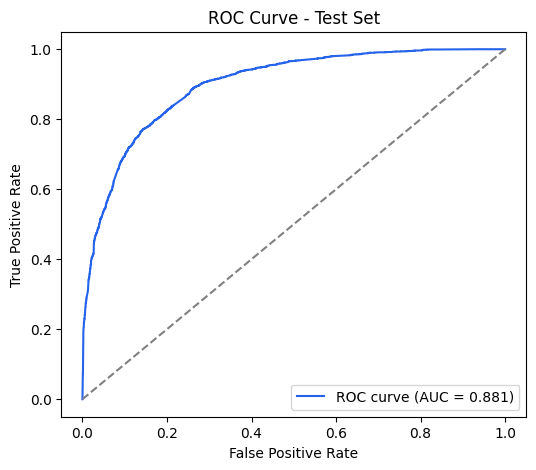

In [24]:
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {test_auc:.3f})', color='#2563eb')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend(loc='lower right')
plt.show()

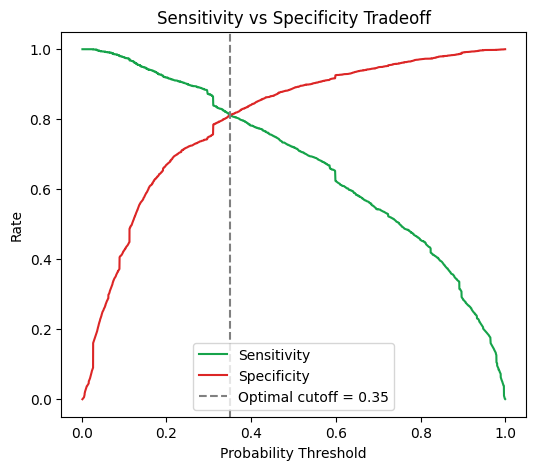

In [25]:
plt.figure(figsize=(6, 5))
plt.plot(thresholds, sensitivity, label='Sensitivity', color='#16a34a')
plt.plot(thresholds, specificity, label='Specificity', color='#dc2626')
plt.axvline(optimal_threshold, linestyle='--', color='gray', label=f'Optimal cutoff = {optimal_threshold:.2f}')
plt.xlabel('Probability Threshold')
plt.ylabel('Rate')
plt.title('Sensitivity vs Specificity Tradeoff')
plt.legend()
plt.show()

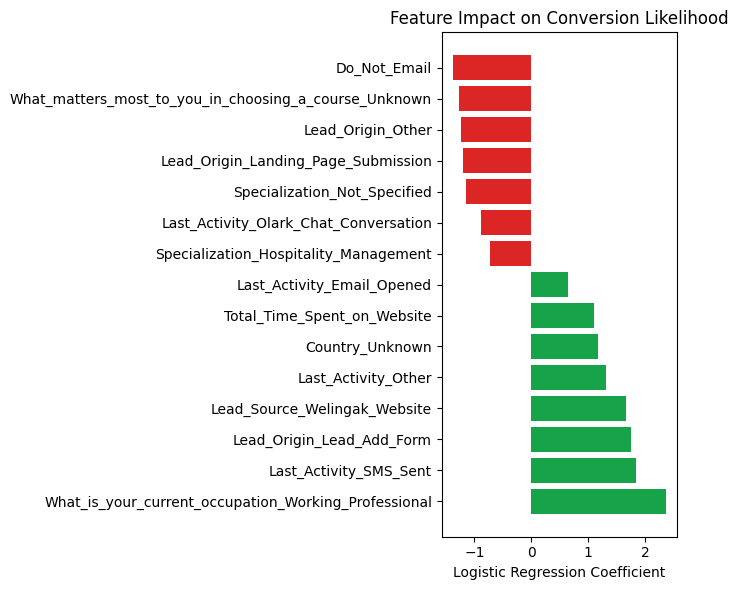

In [26]:
coef_df = pd.DataFrame({
    'Feature': final_features,
    'Coefficient': final_lr.coef_[0]
}).sort_values('Coefficient', ascending=False)

plt.figure(figsize=(7, 6))
colors = ['#dc2626' if c < 0 else '#16a34a' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.xlabel('Logistic Regression Coefficient')
plt.title('Feature Impact on Conversion Likelihood')
plt.tight_layout()
plt.show()

In [27]:
X_all = pd.concat([X_train[final_features], X_test[final_features]])
probs_all = final_lr.predict_proba(X_all)[:, 1]

scores_df = pd.DataFrame({
    'Prospect_ID': ids.loc[X_all.index, 'Prospect ID'].values,
    'Lead_Number': ids.loc[X_all.index, 'Lead Number'].values,
    'Actual_Converted': y.loc[X_all.index].values,
    'Conversion_Probability': probs_all,
    'Lead_Score': (probs_all * 100).round(1)
})
scores_df['Hot_Lead'] = (scores_df['Conversion_Probability'] >= optimal_threshold).astype(int)
scores_df = scores_df.sort_values('Lead_Score', ascending=False)
scores_df.to_csv('scored_leads.csv', index=False)

for cutoff in [50, 60, 70, 80, 90]:
    sub = scores_df[scores_df['Lead_Score'] >= cutoff]
    if len(sub) > 0:
        print(cutoff, len(sub), round(sub['Actual_Converted'].mean() * 100, 1))

files.download('scored_leads.csv')

50 3199 79.6
60 2626 83.1
70 2223 86.0
80 1760 89.7
90 1040 93.8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
with open('model.pkl', 'wb') as f:
    pickle.dump({
        'model': final_lr,
        'features': final_features,
        'scaler': scaler,
        'numeric_cols': NUMERIC_COLS,
        'binary_cols': BINARY_COLS,
        'categorical_cols': CATEGORICAL_COLS,
        'threshold': optimal_threshold,
        'train_columns': X_train.columns.tolist()
    }, f)

files.download('model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MODEL PERFORMANCE
Train AUC:        0.8982
Test AUC:         0.8807
Accuracy:         0.8016
Sensitivity:      0.8024
Specificity:      0.8011
Precision:        0.7166
Optimal threshold: 0.3510

CONFUSION MATRIX (test set)
             Pred: No  Pred: Yes
Actual: No       1365        339
Actual: Yes       211        857

BUSINESS IMPACT — CONVERSION RATE BY SCORE CUTOFF
 Score >=  Leads  Coverage %  Conversion %
       40   3697        40.0          75.0
       50   3199        34.6          79.6
       60   2626        28.4          83.1
       70   2223        24.1          86.0
       80   1760        19.0          89.7
       90   1040        11.3          93.8

TOP 15 FEATURES DRIVING THE SCORE
                                              Feature  Coefficient
 What_is_your_current_occupation_Working_Professional     2.369191
                               Last_Activity_SMS_Sent     1.835517
                            Lead_Origin_Lead_Add_Form     1.758421
                       

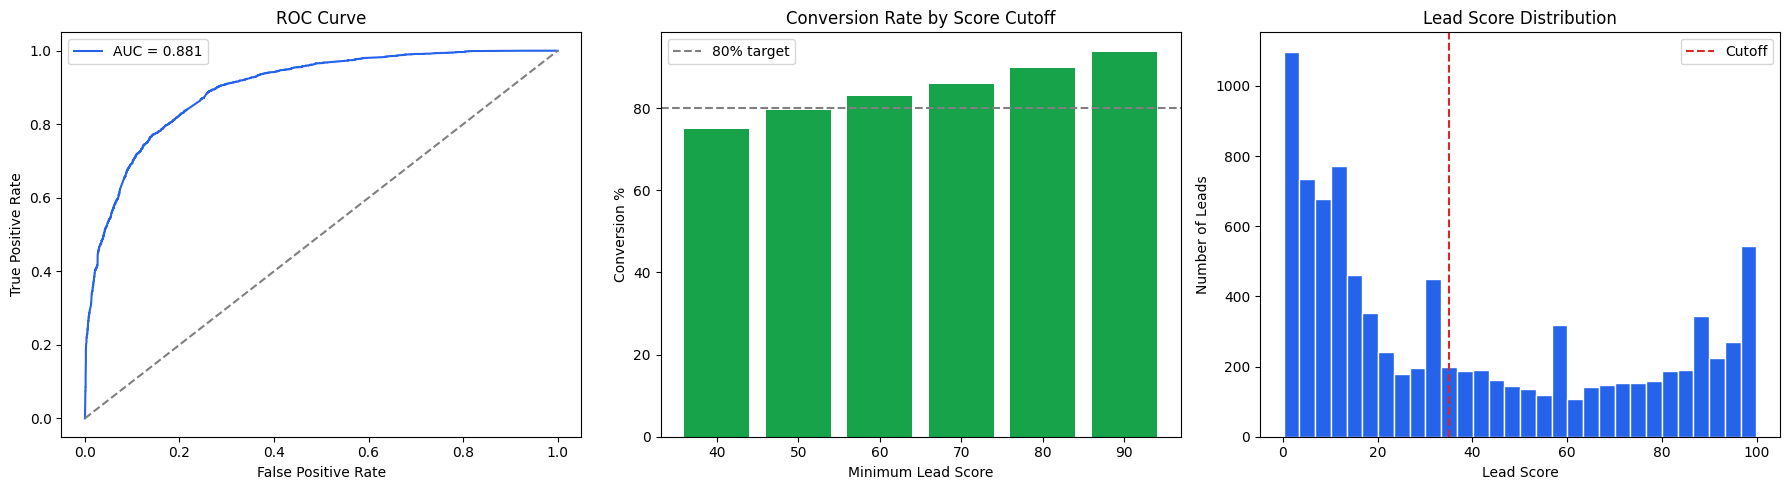

In [29]:
print('=' * 60)
print('MODEL PERFORMANCE')
print('=' * 60)
print(f'Train AUC:        {train_auc:.4f}')
print(f'Test AUC:         {test_auc:.4f}')
print(f'Accuracy:         {accuracy:.4f}')
print(f'Sensitivity:      {sens_test:.4f}')
print(f'Specificity:      {spec_test:.4f}')
print(f'Precision:        {precision_test:.4f}')
print(f'Optimal threshold: {optimal_threshold:.4f}')

print()
print('=' * 60)
print('CONFUSION MATRIX (test set)')
print('=' * 60)
cm_df = pd.DataFrame(cm, index=['Actual: No', 'Actual: Yes'], columns=['Pred: No', 'Pred: Yes'])
print(cm_df)

print()
print('=' * 60)
print('BUSINESS IMPACT — CONVERSION RATE BY SCORE CUTOFF')
print('=' * 60)
cutoff_rows = []
for cutoff in [40, 50, 60, 70, 80, 90]:
    sub = scores_df[scores_df['Lead_Score'] >= cutoff]
    if len(sub) > 0:
        cutoff_rows.append({
            'Score >=': cutoff,
            'Leads': len(sub),
            'Coverage %': round(len(sub) / len(scores_df) * 100, 1),
            'Conversion %': round(sub['Actual_Converted'].mean() * 100, 1)
        })
cutoff_table = pd.DataFrame(cutoff_rows)
print(cutoff_table.to_string(index=False))

print()
print('=' * 60)
print('TOP 15 FEATURES DRIVING THE SCORE')
print('=' * 60)
print(coef_df.to_string(index=False))

print()
print('=' * 60)
print('TOP 10 HIGHEST-SCORED LEADS')
print('=' * 60)
print(scores_df.head(10).to_string(index=False))

print()
print('=' * 60)
print('HOT LEAD SUMMARY')
print('=' * 60)
hot = scores_df[scores_df['Hot_Lead'] == 1]
print(f'Total leads:      {len(scores_df)}')
print(f'Hot leads:        {len(hot)} ({len(hot)/len(scores_df)*100:.1f}% of total)')
print(f'Hot lead conv rate: {hot["Actual_Converted"].mean()*100:.1f}%')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(fpr, tpr, color='#2563eb', label=f'AUC = {test_auc:.3f}')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[0].set_title('ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

axes[1].bar(cutoff_table['Score >='].astype(str), cutoff_table['Conversion %'], color='#16a34a')
axes[1].axhline(80, linestyle='--', color='gray', label='80% target')
axes[1].set_title('Conversion Rate by Score Cutoff')
axes[1].set_xlabel('Minimum Lead Score')
axes[1].set_ylabel('Conversion %')
axes[1].legend()

axes[2].hist(scores_df['Lead_Score'], bins=30, color='#2563eb', edgecolor='white')
axes[2].axvline(optimal_threshold * 100, linestyle='--', color='#dc2626', label='Cutoff')
axes[2].set_title('Lead Score Distribution')
axes[2].set_xlabel('Lead Score')
axes[2].set_ylabel('Number of Leads')
axes[2].legend()

plt.tight_layout()
plt.show()

# Explanation

 Cleaning Up the Data (Preprocessing)
Real-world data is messy, so the first step was making it clean and machine-readable:
Removing "Cheat" Columns: Dropped variables (like 'Tags' or 'Lead Profile') that contain future information and would artificially inflate the model's confidence.  

 Handling Blanks: Filled in missing numerical data (like taking the median for 'TotalVisits') and replaced missing text with 'Unknown' or 'Other' categories.  

Taming Extreme Numbers: Capped extreme outliers at the 1st and 99th percentiles so unusually high or low numbers wouldn't confuse the model.  

Translation for the Computer: Converted "Yes/No" answers into 1s and 0s, and transformed categorical text (like Job Titles or City) into a numerical format using One-Hot Encoding.  

 Finding the Golden Clues (Feature Selection)
Instead of overwhelming the model with every tiny detail, this project uses a strict three-stage filter to isolate only the most powerful predictors:
RFE (Recursive Feature Elimination): An automated process that narrowed the dataset down to the top 20 most important features.  

Removing Repetitive Data (VIF Pruning): A custom function that calculated the Variance Inflation Factor (VIF), automatically dropping features that were too similar to each other (VIF > 5.0) to ensure independent variables.  

Statistical Proof (P-Value Pruning): A final check using statistical modeling to remove any variable that wasn't mathematically proven to impact the outcome (p-value > 0.05).  

Training the Brain (Machine Learning)
The Algorithm: Built a classification model using Logistic Regression to learn the patterns of a successful sale.  
Finding the Sweet Spot: Instead of using a default 50/50 cutoff, the model plotted a mathematical curve (ROC curve) to find the exact optimal probability threshold (~0.351). This point perfectly balances finding as many true buyers as possible without overwhelming the sales team with false alarms.  

Business Impact & Final Results
The model was tested on a completely hidden group of prospects (the test set) and performed exceptionally well:
Accuracy: Successfully predicted the correct outcome ~80.16% of the time.  

Actionable Output: Translated complex machine learning probabilities into an intuitive Lead Score (0-100).  

Hot Leads Identified: Anyone meeting the optimal threshold was officially tagged as a Hot Lead (1), resulting in a focused group of high-potential prospects with an actual conversion rate of over 72%.